На линкот е дадено податочно множество за активноста на студентите во рамките на даден предмет.

- Најнапред, направете Exploratory Data Analysis (EDA) врз податочното множество.
- Потоа, соодветно претпроцесирајте ги податоците.
- На крај, тренирајте и евалуирајте модел по избор за предвидување дали студентот го положил или паднал предметот.

Димензии: (40000, 7)

Први 5 реда:
  Student ID  Study Hours per Week  Attendance Rate  Previous Grades  \
0     S00001                  12.5              NaN             75.0   
1     S00002                   9.3             95.3             60.6   
2     S00003                  13.2              NaN             64.0   
3     S00004                  17.6             76.8             62.4   
4     S00005                   8.8             89.3             72.7   

  Participation in Extracurricular Activities Parent Education Level Passed  
0                                         Yes                 Master    Yes  
1                                          No            High School     No  
2                                          No              Associate     No  
3                                         Yes               Bachelor     No  
4                                          No                 Master     No  

Информации за типовите и нулти вредности:
<class 'pandas.core.f

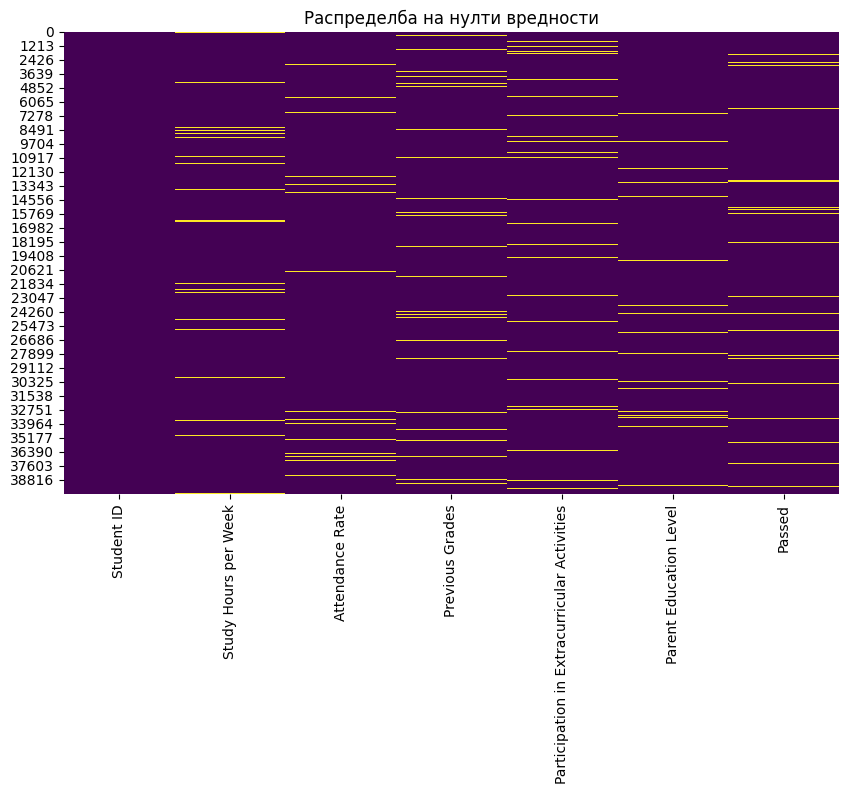

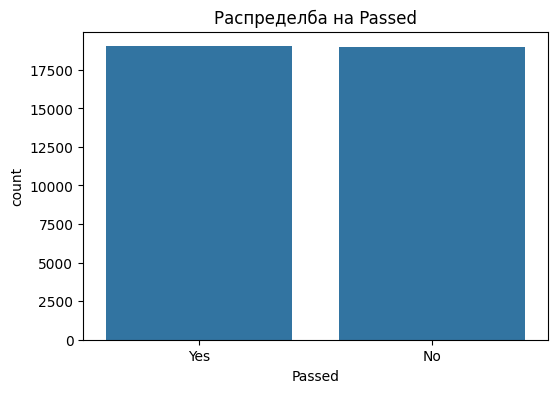

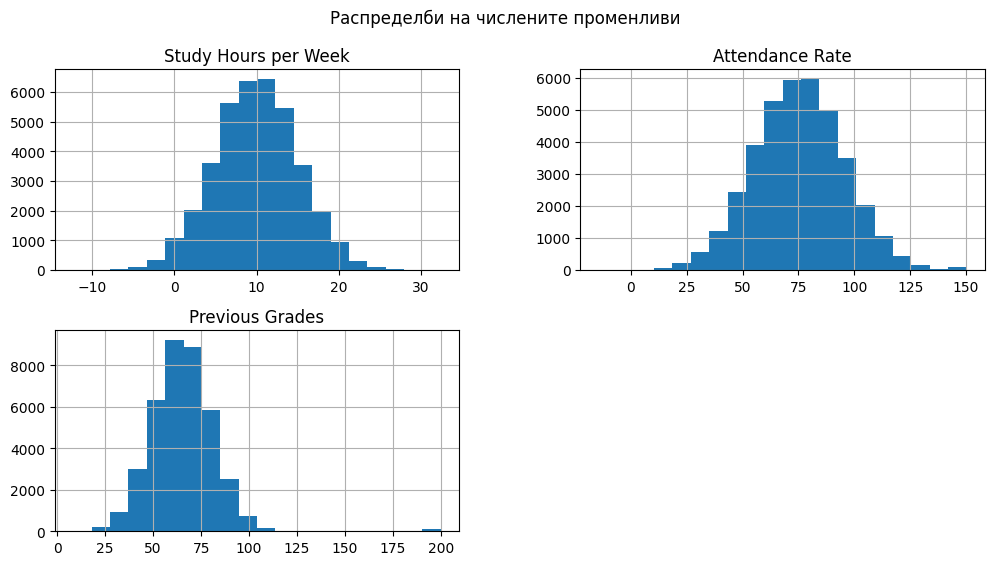

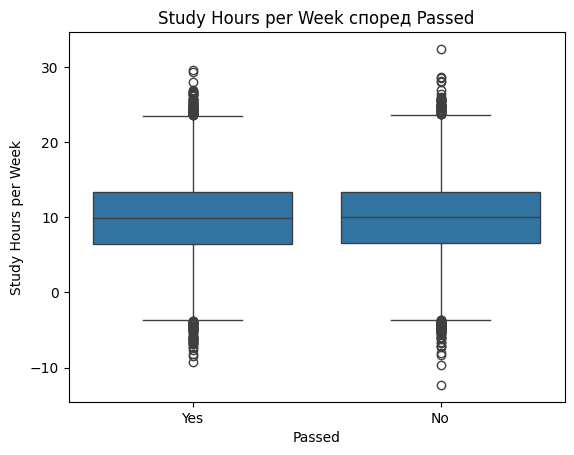

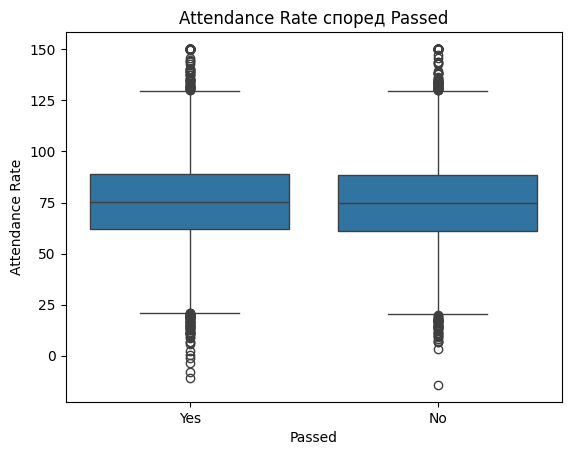

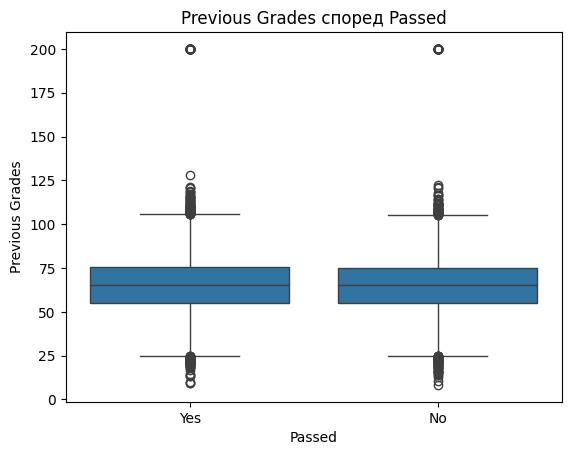

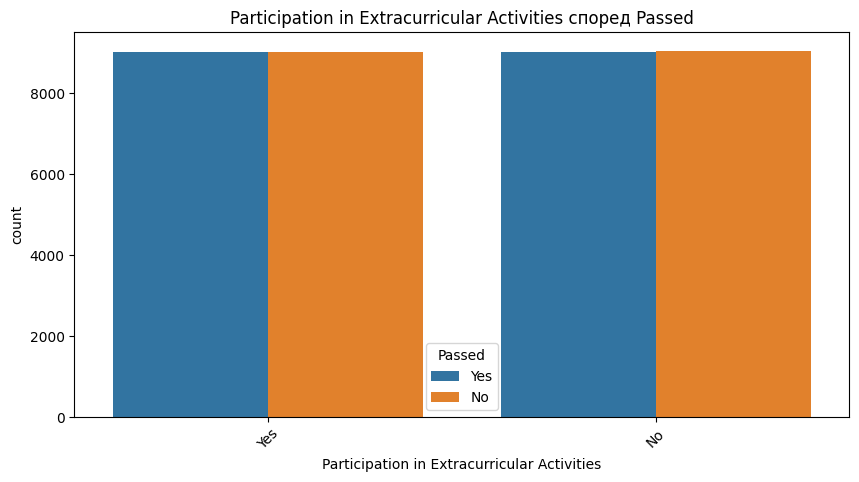

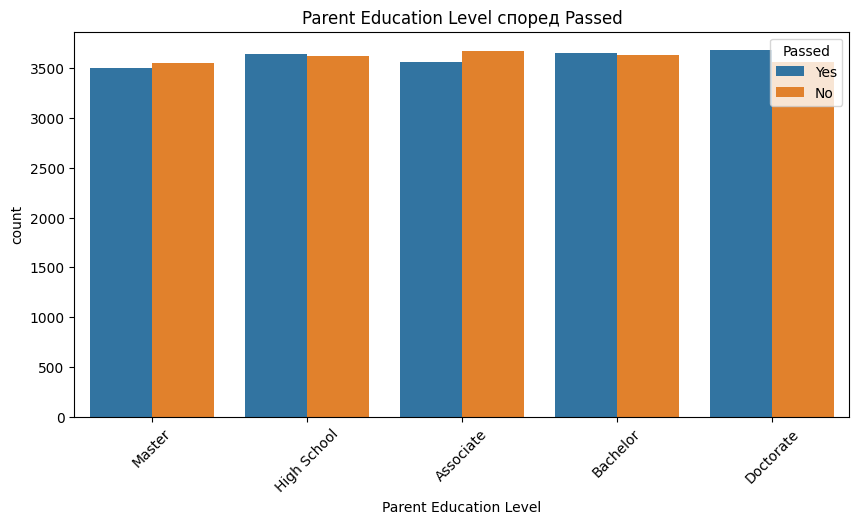

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Вчитување на податоците
df = pd.read_csv("student_performance_prediction.csv")

# Основен преглед
print("Димензии:", df.shape)
print("\nПрви 5 реда:")
print(df.head())

print("\nИнформации за типовите и нулти вредности:")
print(df.info())

print("\nСтатистички преглед на числените колони:")
print(df.describe())

# Проверка на нулти вредности
print("\nНулти вредности по колона:")
print(df.isnull().sum())

# Визуелизација на нулти вредности
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Распределба на нулти вредности")
plt.show()

# Распределба на целната променлива
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Passed')
plt.title("Распределба на Passed")
plt.show()

# Распределби на числените променливи
numerical_cols = ['Study Hours per Week', 'Attendance Rate', 'Previous Grades']
df[numerical_cols].hist(bins=20, figsize=(12, 6))
plt.suptitle("Распределби на числените променливи")
plt.show()

# Визуелизација на односите со целната променлива
for col in numerical_cols:
    plt.figure()
    sns.boxplot(data=df, x='Passed', y=col)
    plt.title(f"{col} според Passed")
    plt.show()

# Распределба на категориските променливи
categorical_cols = ['Participation in Extracurricular Activities', 'Parent Education Level']
for col in categorical_cols:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x=col, hue='Passed')
    plt.title(f"{col} според Passed")
    plt.xticks(rotation=45)
    plt.show()

In [58]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Копирање на податоците
df_clean = df.copy()

# Пополнување на нулти вредности за числени колони
num_imputer = SimpleImputer(strategy='median')
df_clean[numerical_cols] = num_imputer.fit_transform(df_clean[numerical_cols])

# Пополнување на нулти вредности за категориски колони
cat_imputer = SimpleImputer(strategy='most_frequent')
df_clean[categorical_cols] = cat_imputer.fit_transform(df_clean[categorical_cols])

# Целната променлива - отстранување на нулти вредности
df_clean = df_clean.dropna(subset=['Passed'])

# Кодирање на категориски променливи
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(df_clean[col].astype(str))
    label_encoders[col] = le

# Кодирање на целната променлива
df_clean['Passed'] = df_clean['Passed'].map({'Yes': 1, 'No': 0})

# Отстранување на Student ID (не е потребен за моделот)
df_clean = df_clean.drop('Student ID', axis=1)

# Проверка дали има уште нулти вредности
print("Нулти вредности по претпроцесирање:")
print(df_clean.isnull().sum())

# Конечен преглед
print("\nПрви 5 реда по претпроцесирање:")
print(df_clean.head())

Нулти вредности по претпроцесирање:
Study Hours per Week                           0
Attendance Rate                                0
Previous Grades                                0
Participation in Extracurricular Activities    0
Parent Education Level                         0
Passed                                         0
dtype: int64

Први 5 реда по претпроцесирање:
   Study Hours per Week  Attendance Rate  Previous Grades  \
0                  12.5             75.3             75.0   
1                   9.3             95.3             60.6   
2                  13.2             75.3             64.0   
3                  17.6             76.8             62.4   
4                   8.8             89.3             72.7   

   Participation in Extracurricular Activities  Parent Education Level  Passed  
0                                            1                       4       1  
1                                            0                       3       0  
2             

In [59]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import cross_val_score

# Поделба на податоците
X = df_clean.drop('Passed', axis=1)
y = df_clean['Passed']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Стандардизација (доколку е потребно)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Иницијализација и тренирање на моделот
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

# Предвидувања
y_pred = model.predict(X_test_scaled)

# Евалуација
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Вкрстена валидација
cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5)
print(f"CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

# Важност на карактеристиките
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nВажност на карактеристиките:")
print(feature_importance)

Accuracy: 0.5052631578947369

Confusion Matrix:
[[1954 1844]
 [1916 1886]]

Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.51      0.51      3798
           1       0.51      0.50      0.50      3802

    accuracy                           0.51      7600
   macro avg       0.51      0.51      0.51      7600
weighted avg       0.51      0.51      0.51      7600

CV Accuracy: 0.4979 (+/- 0.0054)

Важност на карактеристиките:
                                       feature  importance
1                              Attendance Rate    0.322837
2                              Previous Grades    0.320654
0                         Study Hours per Week    0.288878
4                       Parent Education Level    0.046052
3  Participation in Extracurricular Activities    0.021578
